# Chapitre 2 - Exercices 2.6 à 2.10

Ce notebook traite les exercices 2.6 à 2.10, centrés sur les langages de requête :

- **2.6** : un rapport en pipeline d'agrégation et en SQL (mini-lab) ;
- **2.7** : une généalogie en SQL récursif, et une erreur de saisie qui crée un cycle
  (mini-lab) ;
- **2.8** : une même question en Cypher, SPARQL, Datalog et SQL (mini-lab) ;
- **2.9** : récursion linéaire ou non linéaire en Datalog : tours contre dérivations
  (calcul et mesure) ;
- **2.10** : estimer la sélectivité pour ordonner les motifs d'une requête de
  triplets (calcul).

In [1]:
import itertools
import math
import sqlite3
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 2.6 : un rapport en pipeline d'agrégation et en SQL

**Énoncé.** On reprend les observations d'animaux marins (`dm.make_observations`), et une
collection `observers` (identifiant, nom, club de plongée).

1. Écrire un pipeline d'agrégation qui donne, pour chaque famille et chaque mois d'**été**
   (juin, juillet, août) : le nombre d'observations, le total d'animaux et la taille
   moyenne des groupes, triés par famille puis par mois.
2. Écrire un second pipeline qui donne, pour les requins, le total d'animaux observés par
   **club** (il faut une jointure `$lookup` vers `observers`).
3. Écrire les deux requêtes en SQL sur SQLite et vérifier que les résultats sont égaux.
4. Quel est le rôle de l'étape `$project` dans le pipeline 1 ? Que faudrait-il pour que
   la base exploite un index dans le pipeline 2 ?

**Rappels.** Étapes `$match`, `$project`, `$group`, `$sort`, `$lookup`, `$unwind` ; le
pipeline équivaut à un sous-ensemble de SQL (cours 3, section *MapReduce Querying*).

**Solution.** Les pipelines et les requêtes SQL sont ci-dessous. *4.* `$project` calcule
le mois à partir de l'horodatage pour pouvoir **filtrer dessus** ensuite : notre `$match`
ne compare que des champs. Pour le pipeline 2, placer le `$match` sur `family` **en
premier** permet d'utiliser un index sur ce champ et de ne faire la jointure que sur les
requins ; un index sur `observers._id` (la clé primaire) sert la jointure.

In [2]:
obs = dm.make_observations(20_000, seed=2)
clubs = ["Les Mérous", "Bulles d'Iroise", "Club Calanques", "Nautilus"]
observers = [{"_id": i, "nom": f"plongeur {i}", "club": clubs[i % 4]} for i in range(1, 40)]

PIPE1 = [
    {"$project": {"family": 1, "numAnimals": 1, "mois": {"$month": "$observationTimestamp"}}},
    {"$match": {"mois": {"$in": [6, 7, 8]}}},
    {"$group": {"_id": {"family": "$family", "mois": "$mois"},
                "n": {"$sum": 1}, "total": {"$sum": "$numAnimals"}, "moyenne": {"$avg": "$numAnimals"}}},
    {"$sort": {"_id.family": 1, "_id.mois": 1}},
]
PIPE2 = [
    {"$match": {"family": "Sharks"}},
    {"$lookup": {"from": "observers", "localField": "observer_id", "foreignField": "_id", "as": "obs"}},
    {"$unwind": "$obs"},
    {"$group": {"_id": "$obs.club", "total": {"$sum": "$numAnimals"}}},
    {"$sort": {"total": -1}},
]
r1 = dm.aggregate(obs, PIPE1)
r2 = dm.aggregate(obs, PIPE2, collections={"observers": observers})

con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE observations (id INTEGER PRIMARY KEY, ts TEXT, family TEXT, num INTEGER, observer_id INTEGER)")
con.executemany("INSERT INTO observations VALUES (?, ?, ?, ?, ?)",
                [(o["_id"], o["observationTimestamp"], o["family"], o["numAnimals"], o["observer_id"]) for o in obs])
con.execute("CREATE TABLE observers (id INTEGER PRIMARY KEY, nom TEXT, club TEXT)")
con.executemany("INSERT INTO observers VALUES (?, ?, ?)", [(o["_id"], o["nom"], o["club"]) for o in observers])
SQL1 = """SELECT family, CAST(strftime('%m', ts) AS INTEGER) AS mois, COUNT(*), SUM(num), AVG(num)
            FROM observations WHERE CAST(strftime('%m', ts) AS INTEGER) IN (6, 7, 8)
           GROUP BY family, mois ORDER BY family, mois"""
SQL2 = """SELECT o.club, SUM(x.num) AS total FROM observations x JOIN observers o ON o.id = x.observer_id
           WHERE x.family = 'Sharks' GROUP BY o.club ORDER BY total DESC"""
s1, s2 = con.execute(SQL1).fetchall(), con.execute(SQL2).fetchall()
assert [(r["_id"]["family"], r["_id"]["mois"], r["n"], r["total"]) for r in r1] == [t[:4] for t in s1]
assert np.allclose([r["moyenne"] for r in r1], [t[4] for t in s1])
assert [(r["_id"], r["total"]) for r in r2] == s2
print("pipelines et SQL : résultats identiques")
pd.DataFrame([{"famille": r["_id"]["family"], "mois": r["_id"]["mois"], "observations": r["n"],
               "animaux": r["total"], "taille moyenne": r["moyenne"]} for r in r1]).head(6)

pipelines et SQL : résultats identiques


,famille,mois,observations,animaux,taille moyenne
0,Cetaceans,6,605,1423,2.352
1,Cetaceans,7,610,1328,2.177
2,Cetaceans,8,588,1270,2.160
3,Rays,6,215,432,2.009
4,Rays,7,270,624,2.311
5,Rays,8,268,613,2.287


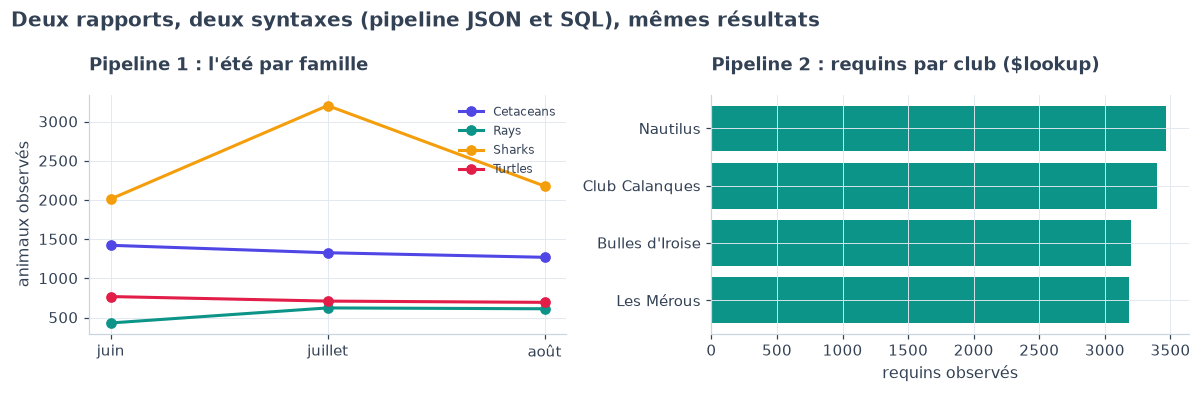

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
t1 = pd.DataFrame([{"famille": r["_id"]["family"], "mois": r["_id"]["mois"], "animaux": r["total"]} for r in r1])
for (fam, sub), col in zip(t1.groupby("famille"), COLORS):
    axes[0].plot(sub["mois"], sub["animaux"], marker="o", color=col, label=fam)
axes[0].set_xticks([6, 7, 8], ["juin", "juillet", "août"]); axes[0].set_ylabel("animaux observés")
axes[0].set_title("Pipeline 1 : l'été par famille"); axes[0].legend(fontsize=8)
axes[1].barh([r["_id"] for r in r2][::-1], [r["total"] for r in r2][::-1], color=TEAL)
axes[1].set_xlabel("requins observés"); axes[1].set_title("Pipeline 2 : requins par club ($lookup)")
finish(fig, "Deux rapports, deux syntaxes (pipeline JSON et SQL), mêmes résultats")

Le pic estival des requins (la saison est simulée dans les données) ressort du premier
rapport. Les deux langages ont exprimé exactement les mêmes calculs : filtre, champ
calculé, regroupement, jointure, tri.

> **À retenir.** Un pipeline d'agrégation se traduit étape par étape en SQL : `$match` =
> `WHERE`, `$project` = expressions du `SELECT`, `$group` = `GROUP BY`, `$lookup` =
> `JOIN`, `$sort` = `ORDER BY`. Filtrer tôt sert les index et réduit la jointure.